# Reading Catalogue Data: Rows, Labels and Missing Outcomes

By Reboot Hub. A 25-minute data-literacy worksheet.

The eight exercise rows below are fictional teaching data. The separate real-case figure reports only the dated 174-row catalogue aggregate, not physical inventory or test results.

## Real dated catalogue aggregate

The chart uses four aggregate facts from Reboot Hub's selected public catalogue
snapshot of **15 October 2026**. These inputs are listing-record counts, not stock
quantities or test outcomes. The fictional exercise starts below this real case.

| Aircraft model | Public listing rows |
| --- | ---: |
| Mini 3 | 32 |
| Mini 3 Pro | 34 |
| Mini 4 Pro | 36 |
| Mini 5 Pro | 72 |
| Selected total | 174 |

All inputs are contained in this notebook. Python 3 and Matplotlib are required
for the chart; the exercise calculations use the Python standard library.
The [full worksheet, source scope and licence](https://reboot-hub.github.io/dji-drone-parts-reference/lessons/catalogue-evidence-lab-20261016/)
provide the companion explanations and downloads.

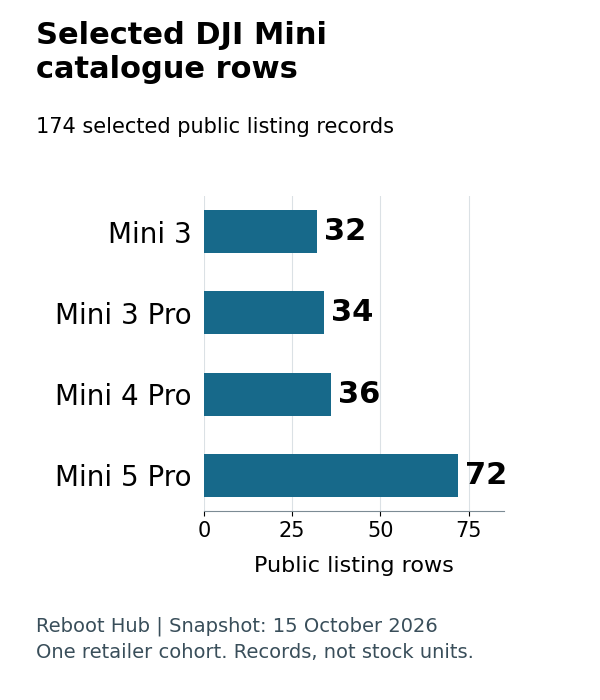

In [1]:
#@title Real catalogue figure: selected listing rows, 15 October 2026
import matplotlib.pyplot as plt
import io
from IPython.display import Image, display

# Four published aggregate facts from one dated retailer cohort.
# This is not the eight-row fictional exercise or an inventory feed.
catalogue_counts = {'Mini 3': 32, 'Mini 3 Pro': 34, 'Mini 4 Pro': 36, 'Mini 5 Pro': 72}
assert sum(catalogue_counts.values()) == 174

with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 18}):
    fig, ax = plt.subplots(figsize=(6, 7), dpi=100)
    fig.subplots_adjust(left=.34, right=.84, top=.72, bottom=.27)
    bars = ax.barh(list(catalogue_counts), list(catalogue_counts.values()),
                   color='#17698A', height=.53)
    ax.invert_yaxis()
    ax.set_xlim(0, 85)
    ax.bar_label(bars, padding=5, fontsize=22, fontweight='bold')
    ax.tick_params(axis='y', length=0, labelsize=20, pad=9)
    ax.set_xticks([0, 25, 50, 75])
    ax.tick_params(axis='x', labelsize=15)
    ax.set_xlabel('Public listing rows', fontsize=16, labelpad=11)
    for edge in ['top', 'right', 'left']:
        ax.spines[edge].set_visible(False)
    ax.spines['bottom'].set_color('#7C8B94')
    ax.xaxis.grid(color='#DBE1E5')
    ax.set_axisbelow(True)
    fig.text(.06, .97, 'Selected DJI Mini\ncatalogue rows',
             fontsize=22, fontweight='bold', va='top')
    fig.text(.06, .81, '174 selected public listing records', fontsize=15)
    fig.text(.06, .12, 'Reboot Hub | Snapshot: 15 October 2026\nOne retailer cohort. Records, not stock units.',
             fontsize=14, color='#394E5A', linespacing=1.5, va='top')
    image_buffer = io.BytesIO()
    fig.savefig(image_buffer, format='png', dpi=100, bbox_inches=None)
    plt.close(fig)
    display(Image(data=image_buffer.getvalue(), width=480))


In [2]:
"""A synthetic classroom exercise; not orders, stock or hardware test records."""
import csv
import json
import re
from collections import Counter
from pathlib import Path


def summarize(rows):
    ids = [r['sample_id'] for r in rows]
    if len(set(ids)) != len(ids):
        raise ValueError('Duplicate sample_id: resolve the record grain first.')
    quantities = [r['stock_quantity'].strip() for r in rows]
    outcomes = [r['test_outcome'].strip().lower() for r in rows]
    if any(x not in ('', 'pass', 'fail') for x in outcomes):
        raise ValueError('Use a recorded pass/fail outcome or leave it missing.')
    observed = [x for x in outcomes if x]
    return {
        'scope': 'fictional teaching fixture only',
        'listing_rows': len(rows),
        'rows_by_family': dict(Counter(r['model_family'] for r in rows)),
        'title_word_faulty_rows': sum(bool(re.search(r'\bfaulty\b', r['item_title'], re.I)) for r in rows),
        'seller_declared_faulty_rows': sum(r['declared_condition'].strip().lower() == 'faulty' for r in rows),
        'stock_quantity_total': sum(int(x) for x in quantities) if quantities and all(x != '' for x in quantities) else None,
        'recorded_test_outcomes': len(observed),
        'missing_test_outcomes': len(rows) - len(observed),
        'failure_fraction_among_recorded_tests': observed.count('fail') / len(observed) if observed else None,
    }



import io
fixture_text = 'sample_id,model_family,item_title,declared_condition,stock_quantity,test_outcome\nS01,Example A,Front left arm,used,,\nS02,Example A,Front right arm,used,,\nS03,Example A,Board - faulty,faulty,,\nS04,Example B,Motor module,used,,\nS05,Example B,Controller cable,open-box,,\nS06,Example B,Camera assembly - faulty,faulty,,\nS07,Example C,Board with cable,used,,\nS08,Example C,Board only,used,,\n'
records = list(csv.DictReader(io.StringIO(fixture_text)))

## Exercise

Count records, then explain why title-word counts, declared condition and independently recorded test outcomes answer different questions. Does a missing quantity mean zero units? Does the absence of a test-outcome column prove that no testing occurred?

In [3]:
answer = summarize(records)
print(json.dumps(answer, indent=2))

{
  "scope": "fictional teaching fixture only",
  "listing_rows": 8,
  "rows_by_family": {
    "Example A": 3,
    "Example B": 3,
    "Example C": 2
  },
  "title_word_faulty_rows": 2,
  "seller_declared_faulty_rows": 2,
  "stock_quantity_total": null,
  "recorded_test_outcomes": 0,
  "missing_test_outcomes": 8,
  "failure_fraction_among_recorded_tests": null
}


## Answer key

Eight fictional records; family counts 3, 3 and 2; two titles contain faulty and two conditions are declared faulty. All stock quantities and test outcomes are missing in the fixture, so neither inventory units nor a failure fraction is available. A missing field is not evidence that an event did not happen. Preserve seller fault disclosures. Title wording is not an independent test record; even not faulty contains the same keyword.

Original lesson, code, figure and synthetic fixture: CC BY 4.0. Linked retailer pages and the separate catalogue dataset retain their own rights. Source context: https://reboot-hub.com/blogs/support-learning/dji-drone-error-codes-technical-reference

In [4]:
assert answer['listing_rows'] == 8
assert answer['stock_quantity_total'] is None
assert answer['failure_fraction_among_recorded_tests'] is None
print('Exercise checks passed: missing values were not replaced by zero or healthy labels.')

Exercise checks passed: missing values were not replaced by zero or healthy labels.
